# M2 — executed data exploration

Real prepared data. No model performance is claimed. Rerun the preparation scripts before this notebook if source versions change. Counts below come from local manifests/CSV tables.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / 'reports').exists(): ROOT = ROOT.parent
REPORTS = ROOT / 'reports'
summary = json.loads((REPORTS / 'eda_summary.json').read_text())
print({k:v for k,v in summary.items() if k != 'manifest_files'})

{'total_rows': 4202, 'total_hours': 17.21052689236111, 'entity_instances': 1482, 'entity_types': 26, 'hindi_source_code_mixing_true': 1973, 'hindi_extempore': 1868, 'pause_instances': 2324, 'hold_instances': 1524, 'eot_instances': 800, 'resampled_rows': 300, 'active_channel_selected_rows': 5, 'text_normalised_rows': 1083, 'source_code_mixing_label_not_independent_language_audit': True}


## Data cards and composition
Three complementary tasks; external benchmarks are not training splits.

In [2]:
display(pd.read_csv(REPORTS / 'tables/source_summary.csv'))
display(pd.read_csv(REPORTS / 'tables/split_summary.csv'))

,source,rows,hours,known_speakers,median_s,q25_s,q75_s,p95_s,min_s,max_s,missing_speaker_rows
0,indiccontext,3102,9.074550,124,9.951000,6.879000,13.792,19.071950,0.353000,26.751,0
1,livekit,800,2.549356,0,8.494375,4.619266,14.925,29.516353,1.914875,85.100,800
2,voicecodebench,300,5.586621,85,65.521250,56.535000,74.550,98.007000,34.920000,122.875,0


,split,rows,hours,known_speakers,pct_of_hindi_development_pool,code_mixing_true,code_mixing_true_pct
0,external_entity_test,300,5.586621,85,NaN,0,NaN
1,external_timing_test,800,2.549356,0,NaN,0,NaN
2,test,467,1.389876,28,15.054803,289,61.884368
3,train,2169,6.236619,65,69.922631,1398,64.453665
4,validation,466,1.448054,31,15.022566,286,61.373391


## Cleaning, formats and duplicates
Retain source membership in external tests. Hindi duplicate utterances remain within connected speaker groups. Raw speech is retained; eight empty native-script references were excluded.

In [3]:
for name in ['audio_format_counts', 'qc_flags', 'duplicates', 'gloss_vocabulary_overlap']:
    print(name)
    display(pd.read_csv(REPORTS / f'tables/{name}.csv'))

audio_format_counts


,source,original_sample_rate,original_channels,selected_channel,rows
0,indiccontext,16000,1,0,3102
1,livekit,16000,1,0,800
2,voicecodebench,48000,1,0,295
3,voicecodebench,48000,2,1,5


qc_flags


,flag,rows
0,clipping_gt_0.1pct,2
1,declared_duration_mismatch,2


duplicates


,source,field,duplicate_groups,additional_rows
0,indiccontext,reference_sha256,7,12
1,indiccontext,audio_sha256,0,0
2,livekit,reference_sha256,13,43
3,livekit,audio_sha256,0,0
4,voicecodebench,reference_sha256,0,0
5,voicecodebench,audio_sha256,0,0


gloss_vocabulary_overlap


,a,b,a_terms,b_terms,shared_terms
0,train,validation,2634,777,352
1,train,test,2634,910,428
2,validation,test,777,910,200


## Statistical analysis
2,000 whole-speaker bootstrap resamples, fixed seed 20261028, percentile 95% intervals. LiveKit lacks grouping IDs, so only descriptive pause summaries are given. These are collected-corpus distributions, not model results or population-wide causal estimates.

In [4]:
display(pd.read_csv(REPORTS / 'tables/statistical_analysis.csv'))
display(pd.read_csv(REPORTS / 'tables/pause_summary.csv'))

,statistic,estimate,ci95_low,ci95_high,groups,resamples,seed
0,indiccontext_mean_duration_s,10.531392,9.919770,11.100643,124,2000,20261028
1,voicecodebench_mean_duration_s,67.039455,64.872922,69.493318,85,2000,20261028
2,hindi_source_label_code_mixing_fraction,0.636041,0.572965,0.695844,124,2000,20261028
3,hindi_read_minus_extempore_mean_duration_s,2.725464,1.886726,3.601660,124,2000,20261028


,language,label,count,median,mean,min,max
0,en,eot,400,1.500000,1.500000,1.500000,1.500000
1,en,hold,850,0.300000,0.463647,0.100000,4.400000
2,hi,eot,400,1.117375,1.168203,0.212688,3.940188
3,hi,hold,674,0.300000,0.334421,0.100000,2.200000


## Figures
English terminal spans are all 1.5s. Do not use future file-end/padding information for endpoint predictions. Source code-mixing flags are not an independent Hinglish audit.

01_corpus_coverage.png


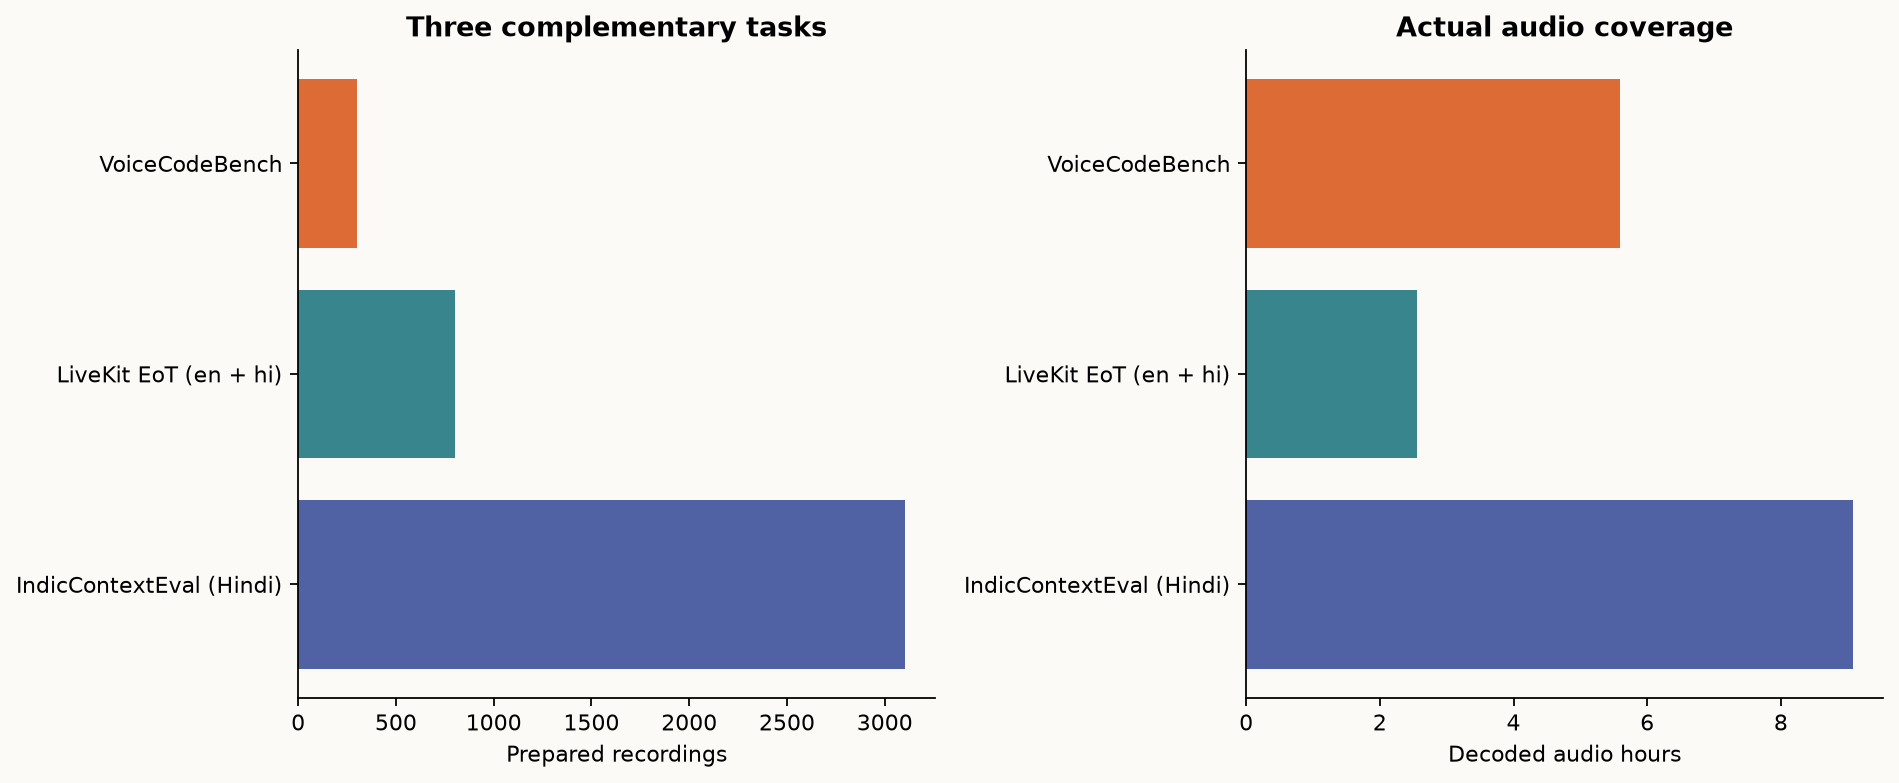

02_entity_coverage.png


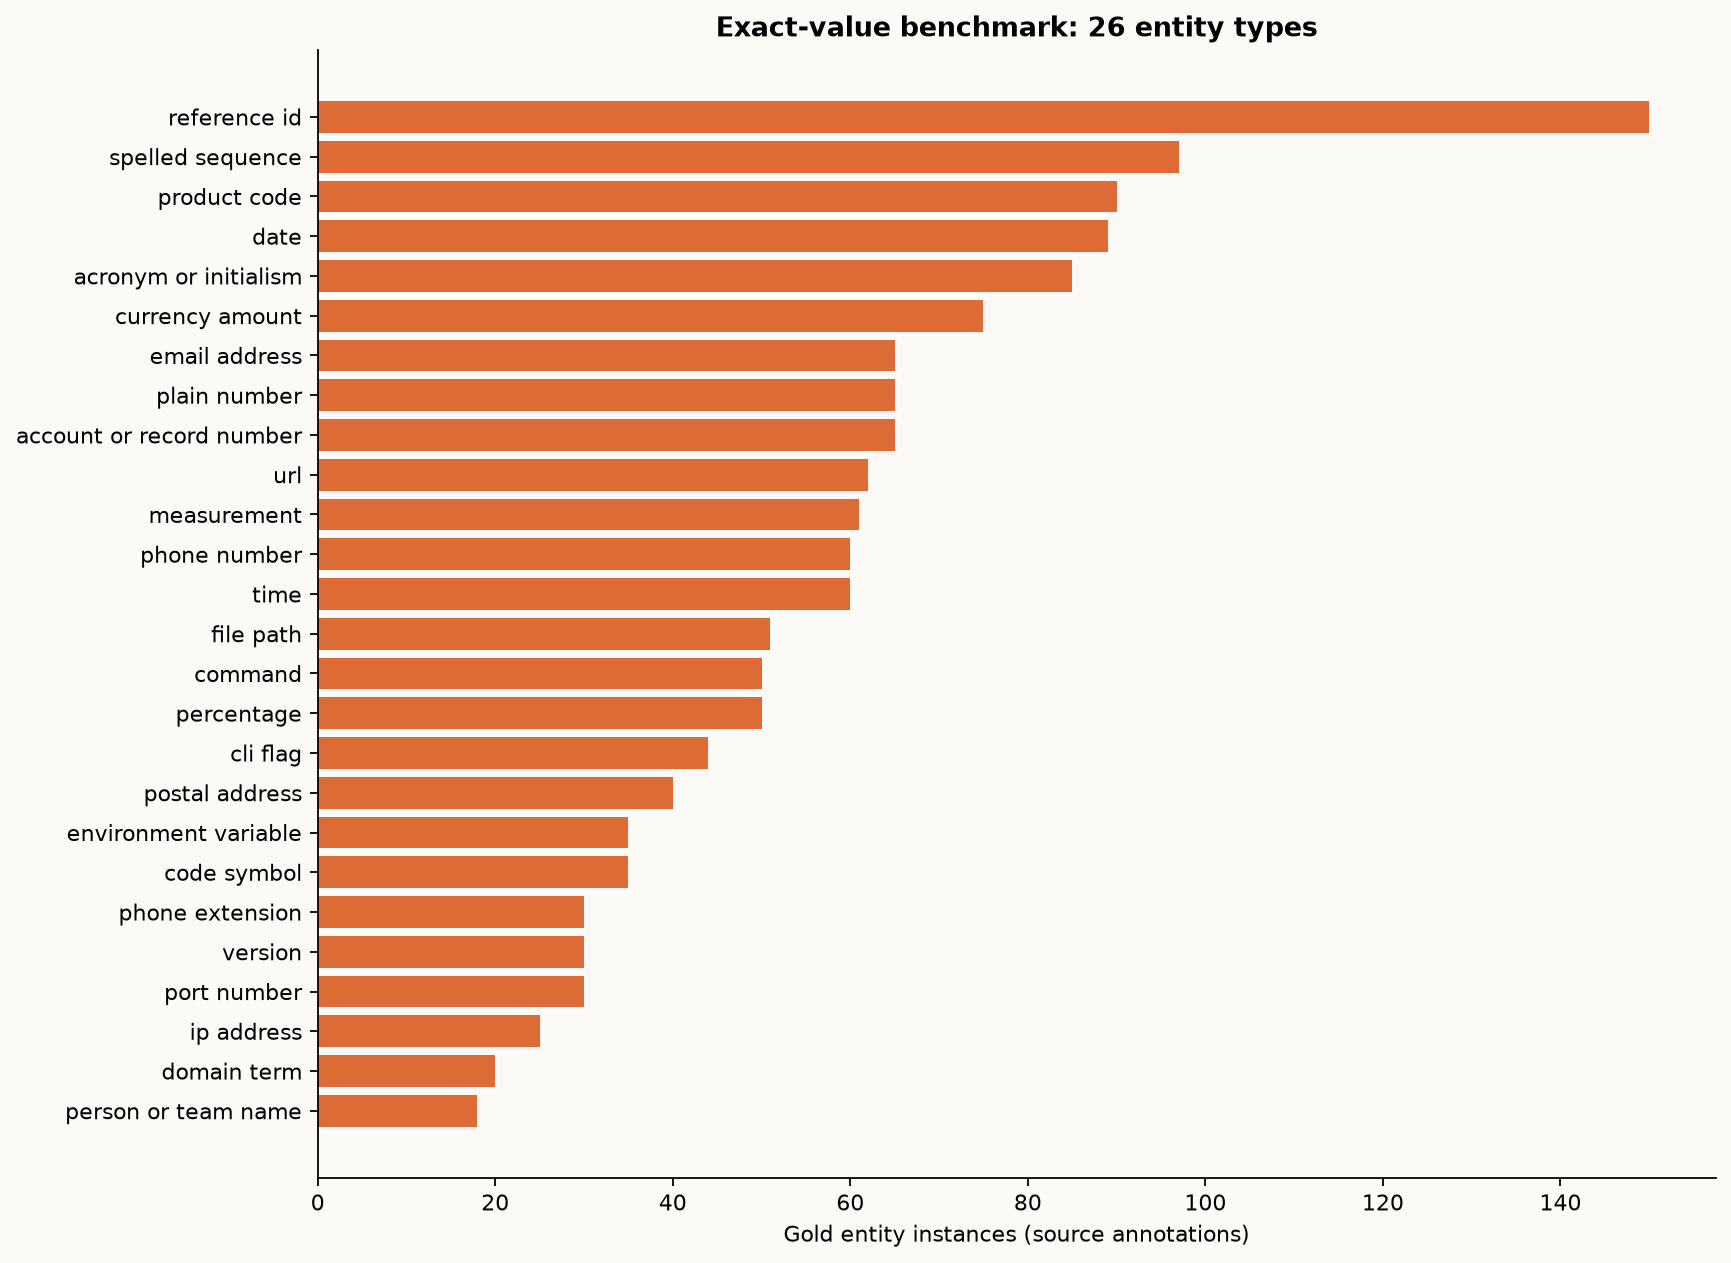

03_duration_distributions.png


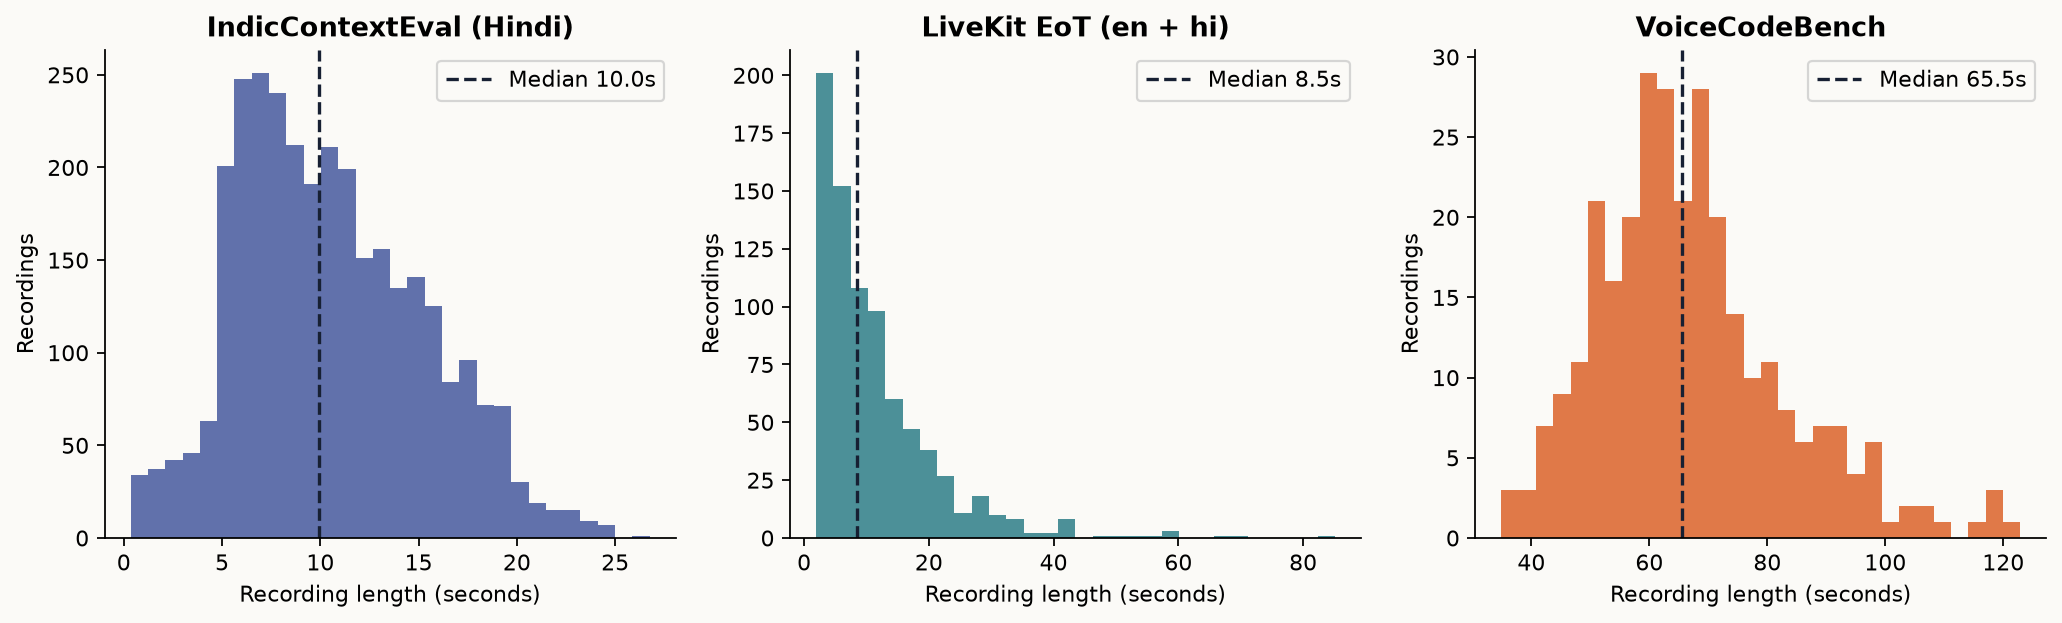

04_split_balance.png


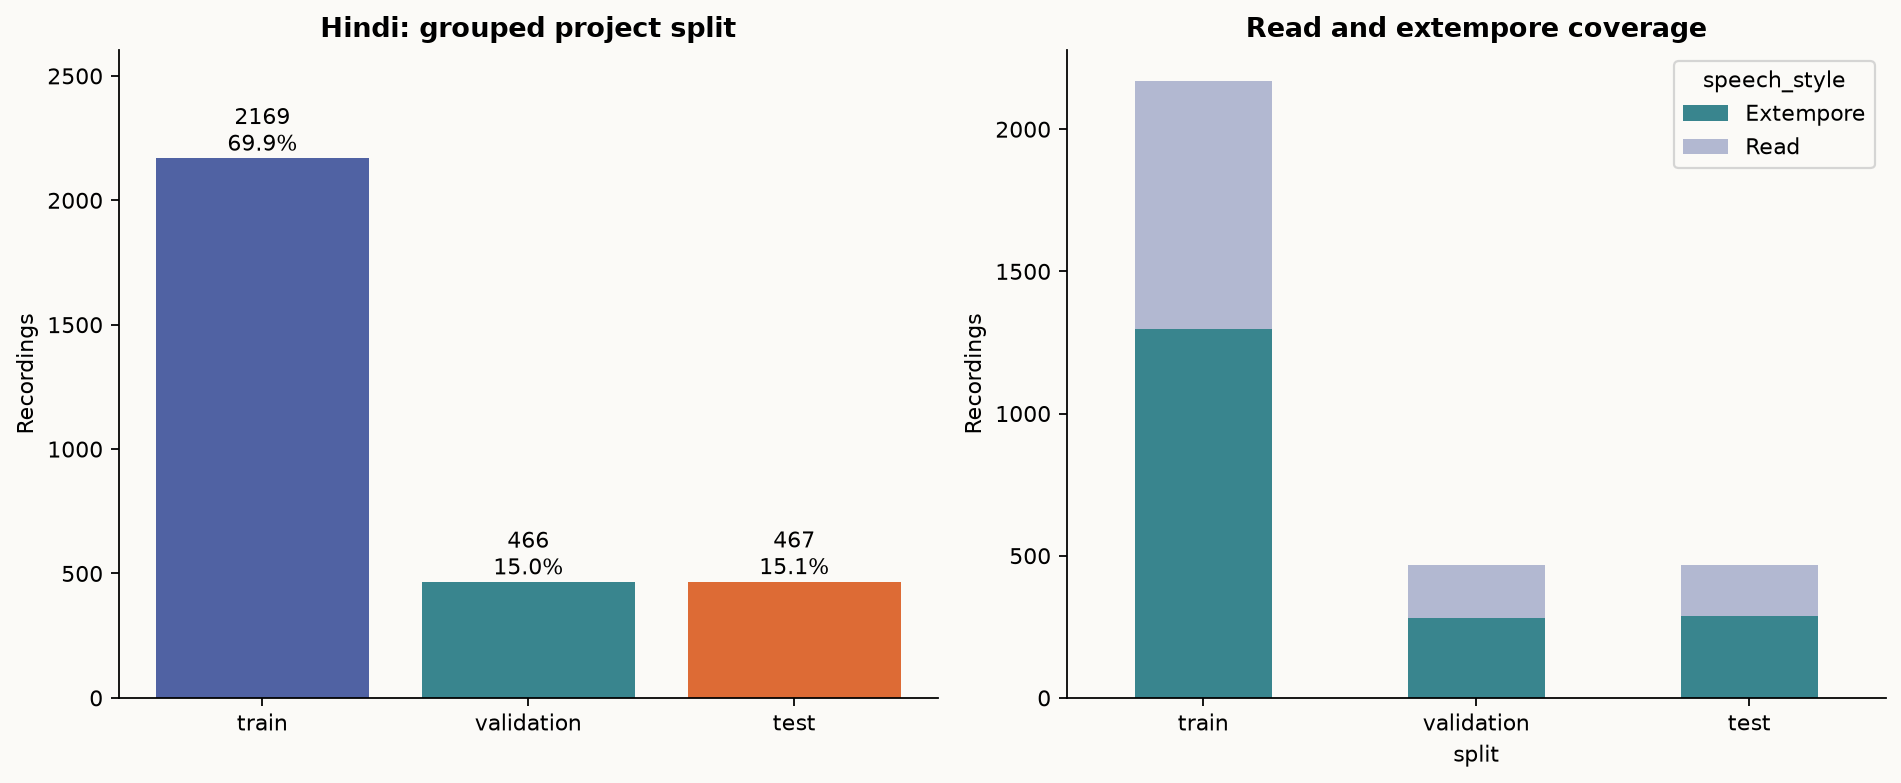

05_pause_distributions.png


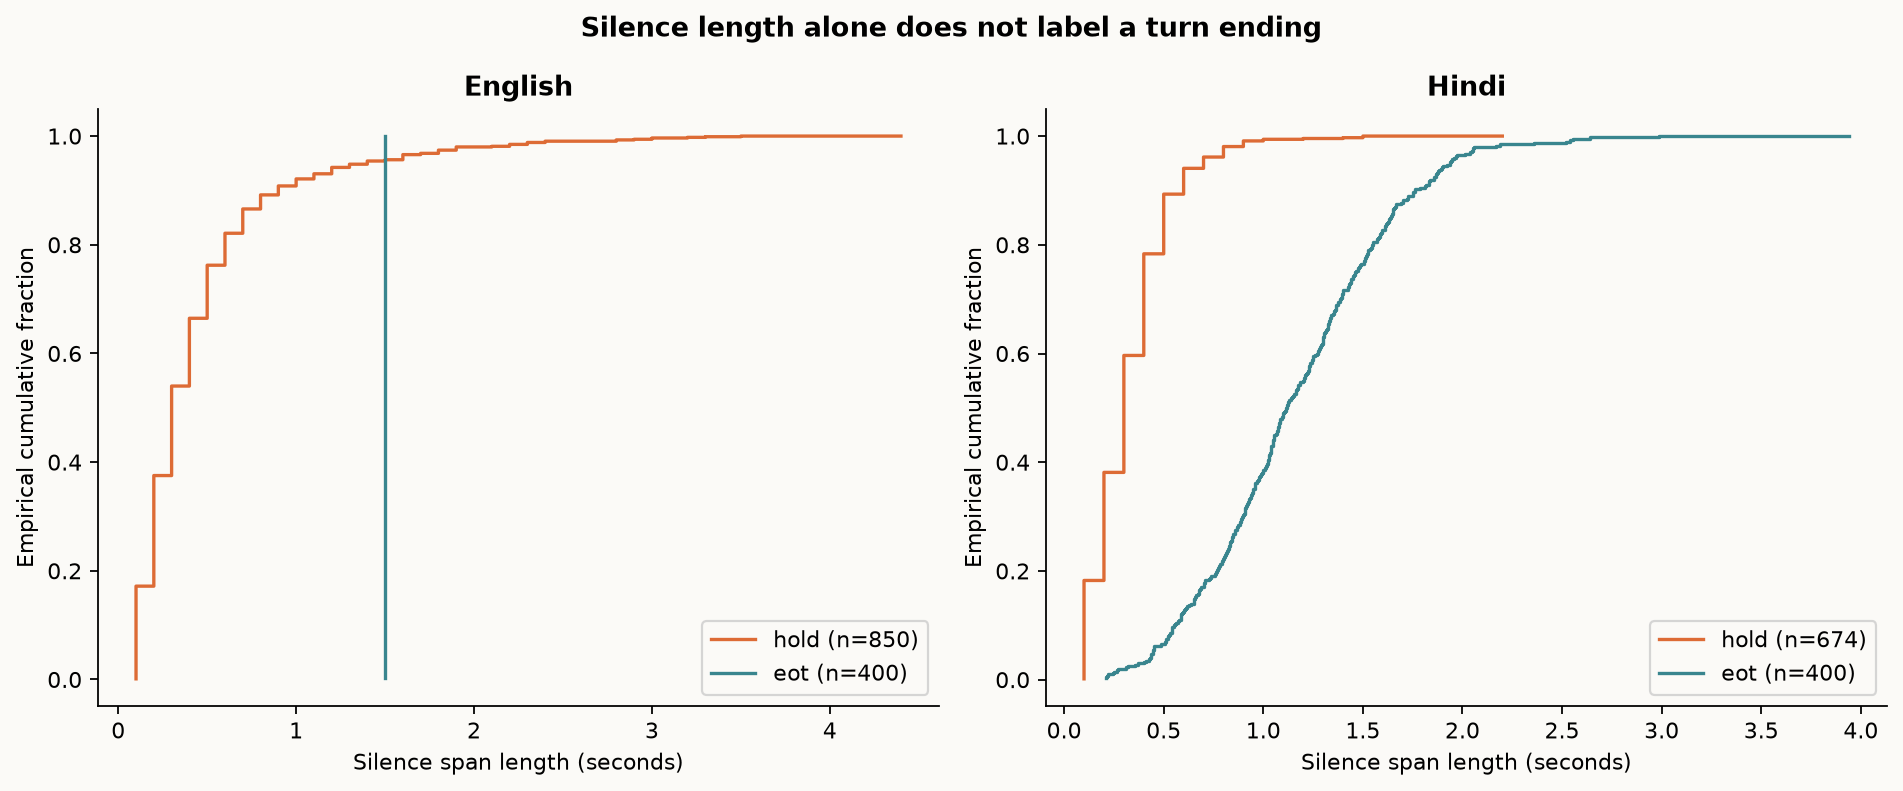

06_hindi_domain_coverage.png


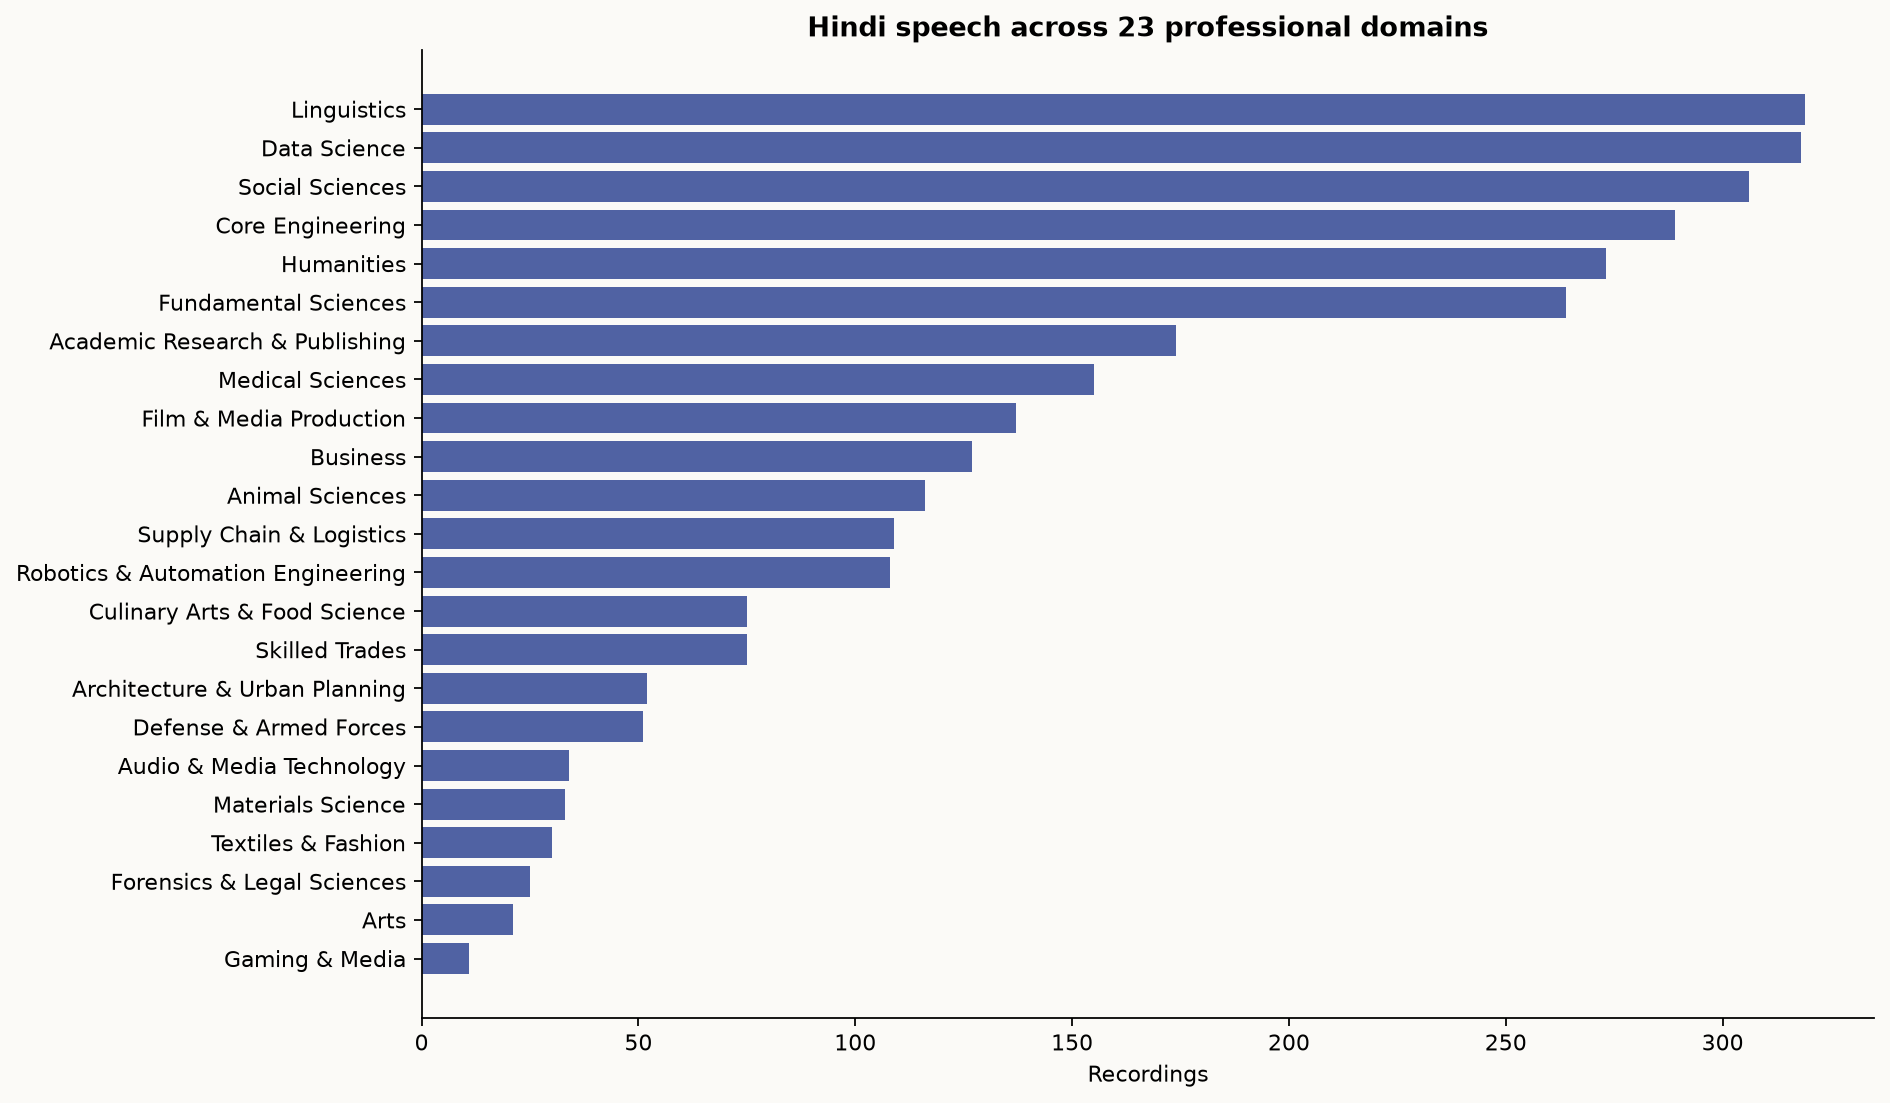

07_audio_quality.png


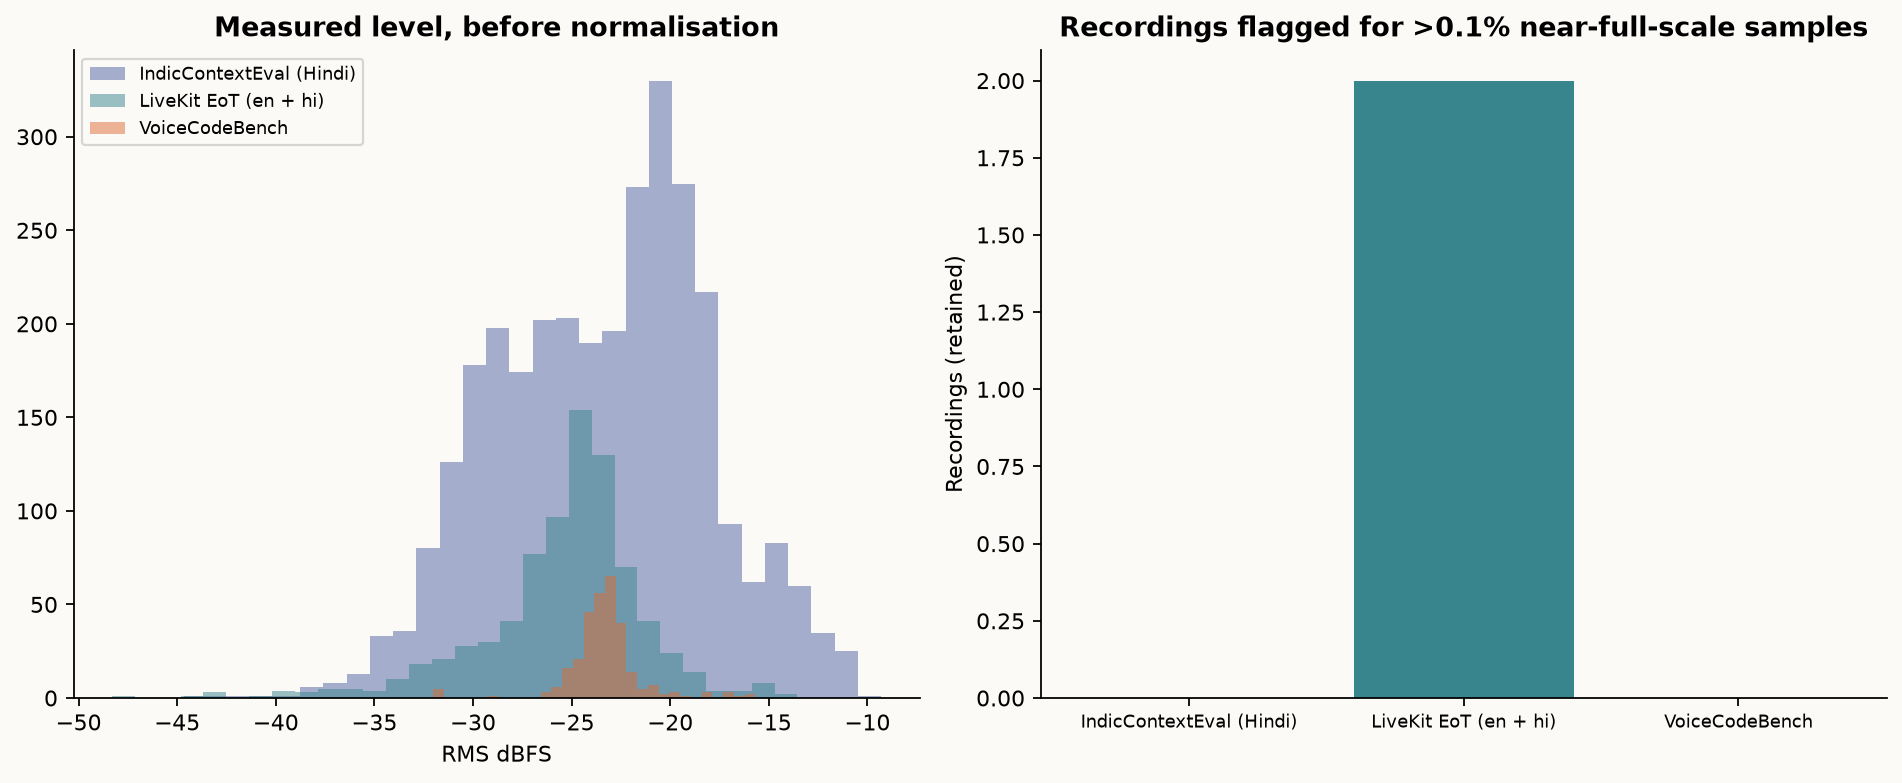

In [5]:
for path in sorted((REPORTS / 'figures').glob('*.png')):
    print(path.name)
    display(Image(filename=str(path)))

## Leakage audit and baseline loader
Gold references live outside inference inputs. Context is an optional fixed prompt condition; no future transcript/word/end labels are input features.

In [6]:
import sys
sys.path.insert(0, str(ROOT))
from src.listening_data import iter_inputs, iter_supervised
audit = json.loads((REPORTS / 'leakage_audit.json').read_text())
assert audit['passed']
assert all(v == 0 for v in audit['overlap_counts'].values())
print(audit)
first = next(iter_inputs('train'))
print('Input fields:', sorted(first))
assert 'reference_nfc' not in first and 'entities' not in first
print('Loader rows:', {s: sum(1 for _ in iter_inputs(s)) for s in ['train', 'validation', 'test', 'external_entity_test', 'external_timing_test']})

{'passed': True, 'sample_ids_unique': True, 'overlap_counts': {'speaker_group:train:validation': 0, 'speaker_group:train:test': 0, 'speaker_group:validation:test': 0, 'reference_sha256:train:validation': 0, 'reference_sha256:train:test': 0, 'reference_sha256:validation:test': 0, 'audio_sha256:train:validation': 0, 'audio_sha256:train:test': 0, 'audio_sha256:validation:test': 0, 'split_component:train:validation': 0, 'split_component:train:test': 0, 'split_component:validation:test': 0, 'external_vs_internal:reference_sha256': 0, 'external_vs_internal:audio_sha256': 0}, 'limitations': ['No verified cross-source speaker identity mapping.', 'No assurance that pretrained vendors never saw public benchmark audio.', 'Distinct domain terms may intentionally recur; exact repeated utterances are grouped.', 'No acoustic near-duplicate or semantic-paraphrase detector; exact hashes only.']}
Input fields: ['audio_path', 'duration_s', 'id', 'language', 'sample_rate', 'source', 'source_revision']
Loa

## Privacy and limitations
Licensed public data; restricted raw audio; no new participants or API uploads. Source notices/privacy policy are under `docs/`. Audio can identify people even after speaker IDs are hashed. Exact overlap checks do not rule out near-duplicates or pretrained-model exposure. Entity audio boundaries and interactive repair outcomes are not invented.